# 9-3. 원 스케일 -- 리샘플링 vs 자체 7분위 구간 비교

**전체 계획** (auto_arima만 사용, GARCH/SV는 나중에)

1. d 고정 (`9-1`: d=1)
2. auto_arima로 p,q 선택 (`9-2`: AICc)
3. **원 스케일: 리샘플링 vs 자체 7분위 비교** (이 노트북)
4. 로그 스케일: 리샘플링 vs 자체 7분위 비교

**공통 조건**: CRPS는 구간의 7분위(10·20·30·50·70·80·90%)로 계산한다.

**비교**: 같은 `auto_arima`(d=1, AICc) 점예측 위에서 구간 생성법만 다르게 한다.
- **자체 구간**: 모델의 정규분포 구간(`conf_int`).
- **리샘플링 구간**: 과거 h단계 예측오차(그 origin 이전에 확정된 것만)에서 **중앙값을 빼 중심화**한 뒤 500개 복원추출해 점예측에 더한 분포. 두 구간의 중심이 같다. auto_arima는 σ가 시점에 따라 변하지 않아(분산 일정) 원 오차를 그대로 쓴다(GARCH·SV는 `9-6`~`9-9`에서 σ_h로 표준화한 오차를 쓴다).

점예측이 같아 MSE는 같고, **커버리지와 CRPS**가 비교 대상이다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE = 1, 500

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    # q7: (7,) 분위수, 2 x mean(pinball) / var_std
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


print(f"전체 origin {len(origins)}개 (origin {origins[0]}~{origins[-1]}), 캘리브레이션 {INITIAL_CALIB}개 ({origins[0]}~{origins[INITIAL_CALIB - 1]}) 이후 채점 origin {len(scored_origins)}개")
print("첫 채점 origin:", label(scored_origins[0]))
print("마지막 채점 origin:", label(scored_origins[-1]))


전체 origin 37개 (origin 20~56), 캘리브레이션 15개 (20~34) 이후 채점 origin 22개
첫 채점 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 채점 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. 두 구간 생성법으로 분위수 만들기

각 origin에서 `auto_arima`(d=1 고정, p,q는 AICc)를 한 번 fit하고 그 점예측 위에서 두 구간을 만든다.

- 자체: 10~90, 20~80, 30~70%는 `conf_int`, 50%는 점예측.
- 리샘플링: `점예측 + (과거 오차 표본 - 그 중앙값)(500개)`의 분위수. 과거 오차는 첫 채점 origin(35)에서 15개, 마지막(56)에서 36개다.
- 커버리지: 90% 구간(자체 `alpha=0.10`, 리샘플링 5~95% 분위수)에 실제값이 들어간 비율.

In [2]:
def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))


def self_quantiles(m):
    fc = np.asarray(m.predict(n_periods=H))
    q = {0.5: fc}
    for alpha in (0.2, 0.4, 0.6):
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=alpha)
        q[round(alpha / 2, 1)], q[round(1 - alpha / 2, 1)] = conf[:, 0], conf[:, 1]
    _, c90 = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return fc, np.array([q[t] for t in LEVELS]), c90  # (7, H), (H, 2)


CACHE = "../cache/cache_93_resample_vs_self_df.pkl"
example = {}
if os.path.exists(CACHE) and "pool_std" in pd.read_pickle(CACHE).columns:
    res = pd.read_pickle(CACHE)
    print(f"캐시에서 로드: {len(res)}행")
else:
    rng = rng_for("X3_l1_9-3_resample_vs_self")
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        train, actual = vals[:o], vals[o:o + H]
        m = pm.auto_arima(train, d=D, seasonal=False, information_criterion="aicc", suppress_warnings=True, error_action="ignore")
        fc, q7_self, c90 = self_quantiles(m)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                samples = fc[h - 1] + rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)
                q7_res = np.quantile(samples, LEVELS)
                lo_r, hi_r = np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])
                sig = max((c90[h - 1, 1] - c90[h - 1, 0]) / (2 * Z), 1e-6)
                mse = ((a - fc[h - 1]) / var_std) ** 2
                rows.append({"origin": o, "h": h, "방식": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "MSE": mse,
                             "CRPS(7분위)": crps7(q7_res, a),
                             "구간폭": (hi_r - lo_r) / var_std, "lo": lo_r, "hi": hi_r, "fc": fc[h - 1], "actual": a,
                             "pool_n": len(pool[h]), "pool_std": pool[h].std(), "pool_absmax": np.abs(pool[h]).max()})
                rows.append({"origin": o, "h": h, "방식": "자체", "적중": float(c90[h - 1, 0] <= a <= c90[h - 1, 1]) * 100, "MSE": mse,
                             "CRPS(7분위)": crps7(q7_self[:, h - 1], a),
                             "구간폭": (c90[h - 1, 1] - c90[h - 1, 0]) / var_std,
                             "lo": c90[h - 1, 0], "hi": c90[h - 1, 1], "fc": fc[h - 1], "actual": a, "sigma_model": sig})
                if o == scored_origins[0] and h == H:
                    example = {"samples": samples, "fc": fc[h - 1], "sig": sig, "q_res": q7_res, "q_self": q7_self[:, h - 1],
                               "actual": a, "lo_r": lo_r, "hi_r": hi_r, "lo_n": c90[h - 1, 0], "hi_n": c90[h - 1, 1]}
        for h in range(1, H + 1):
            pool[h] = np.append(pool[h], actual[h - 1] - fc[h - 1])
    res = pd.DataFrame(rows)
    res.to_pickle(CACHE)
    pd.to_pickle(example, CACHE.replace(".pkl", "_example.pkl"))
    print(f"계산 완료: {len(res)}행 (origin {res['origin'].nunique()}개 x h {H} x 방식 2)")
if not example:
    example = pd.read_pickle(CACHE.replace(".pkl", "_example.pkl"))


캐시에서 로드: 176행


### 1-1. 구조 보기

같은 origin(35, 예측 2019Q4~2020Q3), h=4의 **같은 점예측** 위에서 두 방식이 어떤 분포와 7분위를 만드는지 본다. 선은 7분위(10·20·30·50·70·80·90%)다.


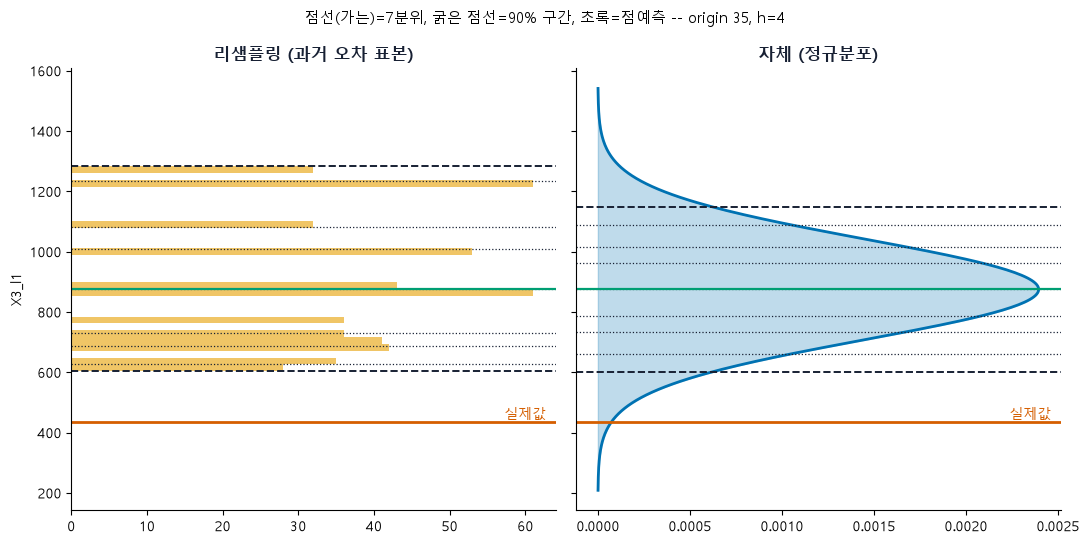

In [3]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ex = example
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
axes[0].hist(ex["samples"], bins=30, color="#E69F00", alpha=0.6, orientation="horizontal")
for q in ex["q_res"]:
    axes[0].axhline(q, color="#172033", linewidth=0.9, linestyle=":")
axes[0].axhline(ex["lo_r"], color="#172033", linestyle="--", linewidth=1.4)
axes[0].axhline(ex["hi_r"], color="#172033", linestyle="--", linewidth=1.4)
axes[0].set_title("리샘플링 (과거 오차 표본)", fontsize=12, fontweight="bold", color="#172033")
yy = np.linspace(ex["fc"] - 4 * ex["sig"], ex["fc"] + 4 * ex["sig"], 300)
axes[1].plot(stats.norm.pdf(yy, ex["fc"], ex["sig"]), yy, color="#0072B2", linewidth=2)
axes[1].fill_betweenx(yy, 0, stats.norm.pdf(yy, ex["fc"], ex["sig"]), color="#0072B2", alpha=0.25)
for q in ex["q_self"]:
    axes[1].axhline(q, color="#172033", linewidth=0.9, linestyle=":")
axes[1].axhline(ex["lo_n"], color="#172033", linestyle="--", linewidth=1.4)
axes[1].axhline(ex["hi_n"], color="#172033", linestyle="--", linewidth=1.4)
axes[1].set_title("자체 (정규분포)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.axhline(ex["actual"], color="#D55E00", linewidth=2)
    ax.text(ax.get_xlim()[1] * 0.98, ex["actual"], " 실제값", color="#D55E00", ha="right", va="bottom", fontsize=10)
    ax.axhline(ex["fc"], color="#009E73", linewidth=1.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("X3_l1")
fig.suptitle("점선(가는)=7분위, 굵은 점선=90% 구간, 초록=점예측 -- origin 35, h=4", fontsize=11)
fig.tight_layout()
plt.show()


## 2. 결과 -- 22개 origin 전체 평균

22개 origin x h=1~4 = 88개를 방식별로 평균한다. 구간폭은 90% 구간의 폭을 `var_std`로 나눈 값이다. MSE는 같은 점예측을 공유하므로 같아야 한다.

In [4]:
cols = ["적중", "MSE", "CRPS(7분위)", "구간폭"]
summary = res.groupby("방식")[cols].mean().rename(columns={"적중": "커버리지(%)"}).round(3)
display(summary)
print("MSE 차이(두 방식):", float((res[res["방식"] == "리샘플링"]["MSE"].values - res[res["방식"] == "자체"]["MSE"].values).max()))

print("h별:")
display(res.groupby(["방식", "h"])[["적중", "CRPS(7분위)", "구간폭"]].mean().rename(columns={"적중": "커버리지(%)"}).round(3).unstack("방식"))


,커버리지(%),MSE,CRPS(7분위),구간폭
방식,,,,
리샘플링,69.318,1.164,0.598,2.227
자체,61.364,1.164,0.621,1.705


MSE 차이(두 방식): 0.0
h별:


커버리지(%)         CRPS(7분위)           구간폭       
방식    리샘플링      자체      리샘플링     자체   리샘플링     자체
h                                                
1   72.727  59.091     0.322  0.314  1.118  0.813
2   59.091  59.091     0.561  0.560  1.880  1.476
3   72.727  59.091     0.659  0.727  2.533  2.031
4   72.727  68.182     0.852  0.883  3.377  2.501

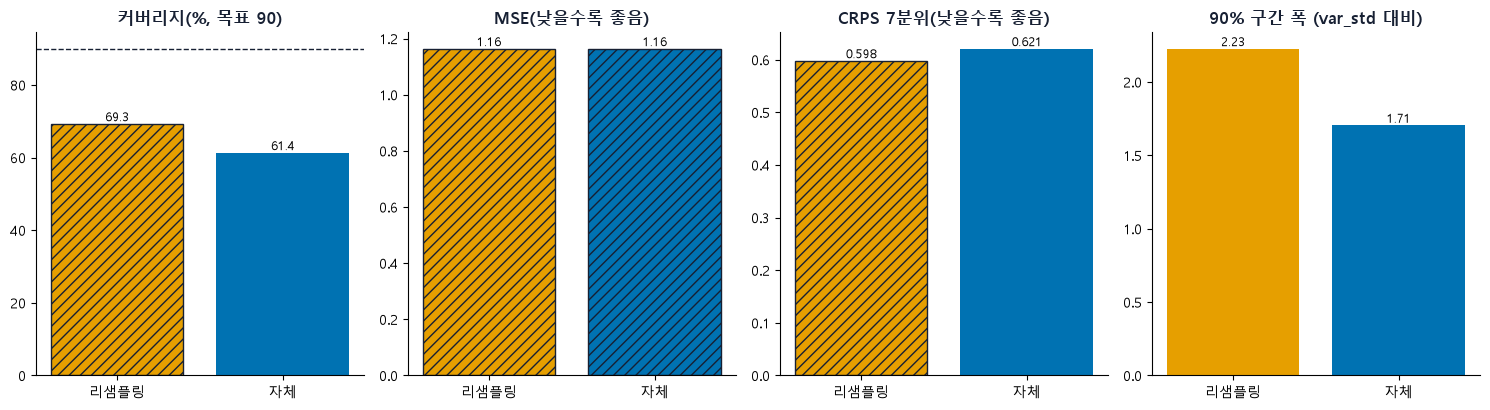

In [5]:
colr = {"리샘플링": "#E69F00", "자체": "#0072B2"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (c, t) in zip(axes, [("커버리지(%)", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)"), ("구간폭", "90% 구간 폭 (var_std 대비)")]):
    bars = ax.bar(summary.index, summary[c], color=[colr[i] for i in summary.index])
    if c != "구간폭":   # 폭은 좋고 나쁨이 없어 1등 표시를 하지 않는다
        score = (summary[c] - 90).abs() if c.startswith("커버리지") else summary[c]
        for b, k in zip(bars, summary.index):
            if score[k] <= score.min() + 1e-9:   # 1등(동률이면 모두)에 빗금
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지(%)":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 3. origin별 추이

두 방식의 커버리지와 CRPS가 origin마다 어떻게 다른지 본다(origin당 h=1~4 평균, 예측 시작 분기 표기). 평가는 위의 22개 전체 평균이고, 이 그림은 차이가 특정 구간에 몰려 있는지 확인하는 용도다.


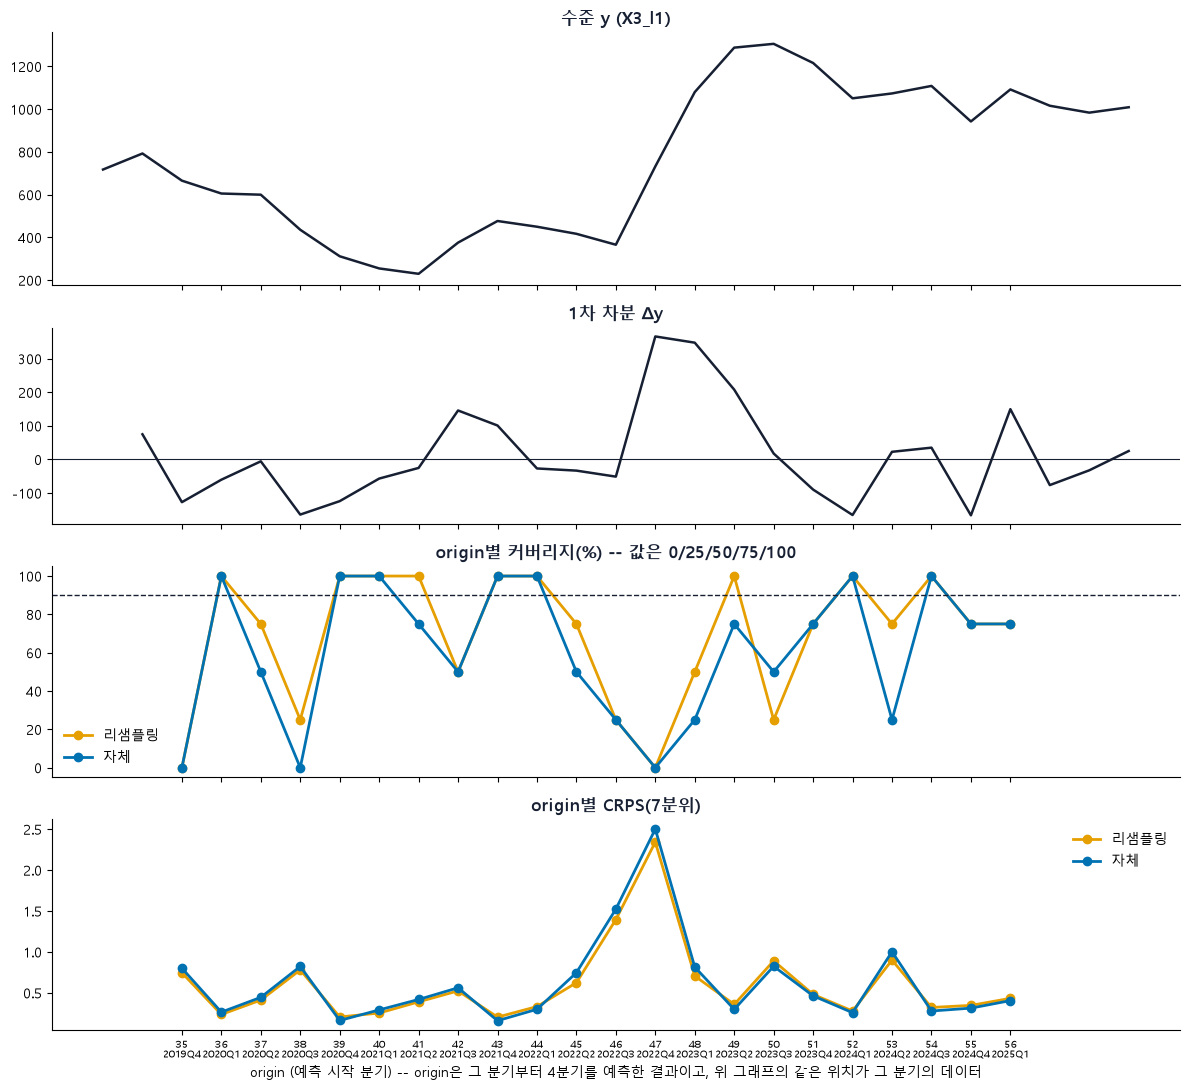

In [6]:
per = res.groupby(["방식", "origin"])[["적중", "CRPS(7분위)"]].mean()
xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2          # 첫 origin 직전 데이터부터 보여 준다
tt = np.arange(t0, len(vals))       # x축 = 분기 번호(origin n은 n번째 분기부터 예측)
dyv = np.diff(vals)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.8, 1.4, 1.5, 1.5]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax, c, t in [(axes[2], "적중", "origin별 커버리지(%) -- 값은 0/25/50/75/100"), (axes[3], "CRPS(7분위)", "origin별 CRPS(7분위)")]:
    for name in ["리샘플링", "자체"]:
        ax.plot(scored_origins, per.loc[name][c].values, marker="o", color=colr[name], linewidth=2, label=name)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.legend(frameon=False)
axes[2].axhline(90, color="#172033", linestyle="--", linewidth=1)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- origin은 그 분기부터 4분기를 예측한 결과이고, 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


## 4. 결론

**리샘플링이 커버리지가 더 높고 CRPS(7분위)도 약간 낫지만, 구간이 31% 더 넓고 차이는 크지 않다.** (오차 표본 중심화로 두 방식의 점예측과 구간 중심이 같다.)

| 방식 | 커버리지(%) | MSE | CRPS(7분위) | 90% 구간 폭 |
|---|---|---|---|---|
| 리샘플링 | 69.3 | 1.164 | 0.598 | 2.23 |
| 자체(정규분포) | 61.4 | 1.164 | 0.621 | 1.71 |

- **MSE 같음**, **커버리지** 리샘플링 +8.0%p(둘 다 목표 90%에 크게 못 미침).
- **CRPS(7분위)** 리샘플링 0.598 vs 자체 0.621(3.7% 낮음). h=1·2는 비슷하고, h=3·4는 리샘플링이 낫다(0.659 vs 0.727, 0.852 vs 0.883).
- 리샘플링의 커버리지 이점은 구간이 넓어서 생긴 부분이 크다(폭 2.23 vs 1.71).
- origin별로는 CRPS 곡선이 거의 겹치고, 두 방식 모두 origin 35, 47(급등기)에서 커버리지 0%다.
- 이전(8-1, d=0 위주)에는 리샘플링 73.9% vs 자체 51.1%(22.8%p 차)였는데, d=1 고정으로 8.0%p로 줄었다.

**한계**: 리샘플링의 과거 오차 표본이 처음엔 15개뿐이라 분포가 거칠다. 22개 origin이 겹쳐 유의성은 검증하지 않았다.

**다음 단계**: `9-4`에서 같은 비교를 로그 스케일에서 한다.

## 5. 두 방식의 차이 분석 (추가 연구)

리샘플링과 자체 구간의 차이가 **실제로 있는지, 폭 때문인지** 본다. 검정(부트스트랩·DM)은 쓰지 않는다.

1. **짝지은 차이**: 같은 origin에서 (리샘플링 - 자체)를 구해 일관성(앞선 origin 수)과 쏠림을 본다.
2. **같은 폭에서 비교**:
   - **구간 점수(α=0.10)**: `폭 + (2/α) x 벗어난 거리`를 `var_std`로 나눈 값 (Gneiting & Raftery, 2007의 interval score를 α=0.10으로 적용). 낮을수록 좋다.
   - **90% 도달 배율 k**: 구간을 점예측 중심으로 k배 늘려 88개 전체 커버리지가 90%가 되는 최소 k와 그때의 폭.

In [7]:
DF = res.copy()
ALPHA_IS = 0.10
DF["구간점수"] = ((DF["hi"] - DF["lo"]) + (2 / ALPHA_IS) * np.maximum(DF["lo"] - DF["actual"], 0)
              + (2 / ALPHA_IS) * np.maximum(DF["actual"] - DF["hi"], 0)) / var_std

po = DF.groupby(["방식", "origin"])[["CRPS(7분위)", "구간점수", "적중", "구간폭"]].mean()
dif = po.loc["리샘플링"] - po.loc["자체"]        # 리샘플링 - 자체 (origin별)
rows = []
for c, better in [("CRPS(7분위)", "neg"), ("구간점수", "neg"), ("적중", "pos")]:
    d_ = dif[c]
    n_better = int((d_ < -1e-9).sum()) if better == "neg" else int((d_ > 1e-9).sum())
    n_worse = int((d_ > 1e-9).sum()) if better == "neg" else int((d_ < -1e-9).sum())
    rows.append({"지표": c.replace("적중", "커버리지(%)"), "평균 차이": d_.mean(), "중앙값 차이": d_.median(),
                 "리샘플링이 앞선 origin": n_better, "뒤진 origin": n_worse, "같은 origin": len(d_) - n_better - n_worse})
display(pd.DataFrame(rows).set_index("지표").round(3))
print("차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.")

split = np.where(dif.index <= 46, "origin 35~46 (예측 시작 2022Q3 이전)", "origin 47~56 (2022Q4 이후)")
print("구간별 평균 차이 (리샘플링 - 자체):")
display(dif.groupby(split).mean().rename(columns={"적중": "커버리지(%)"}).round(3))
hdiff = (DF[DF["방식"] == "리샘플링"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean()
         - DF[DF["방식"] == "자체"].groupby("h")[["CRPS(7분위)", "구간점수", "적중"]].mean())
print("h별 평균 차이 (리샘플링 - 자체):")
display(hdiff.rename(columns={"적중": "커버리지(%)"}).round(3))


,평균 차이,중앙값 차이,리샘플링이 앞선 origin,뒤진 origin,같은 origin
지표,,,,,
CRPS(7분위),-0.023,-0.029,12,10,0
구간점수,-0.830,0.224,9,13,0
커버리지(%),7.955,0.000,7,1,14


차이 = 리샘플링 - 자체. CRPS·구간점수는 음수면 리샘플링이 낫고, 커버리지는 양수면 리샘플링이 높다. 22개 origin 기준.
구간별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%),구간폭
origin 35~46 (예측 시작 2022Q3 이전),-0.033,-0.574,8.333,0.389
origin 47~56 (2022Q4 이후),-0.010,-1.136,7.500,0.681


h별 평균 차이 (리샘플링 - 자체):


,CRPS(7분위),구간점수,커버리지(%)
h,,,
1,0.007,-0.554,13.636
2,0.001,-1.038,0.000
3,-0.068,-0.445,13.636
4,-0.031,-1.283,4.545


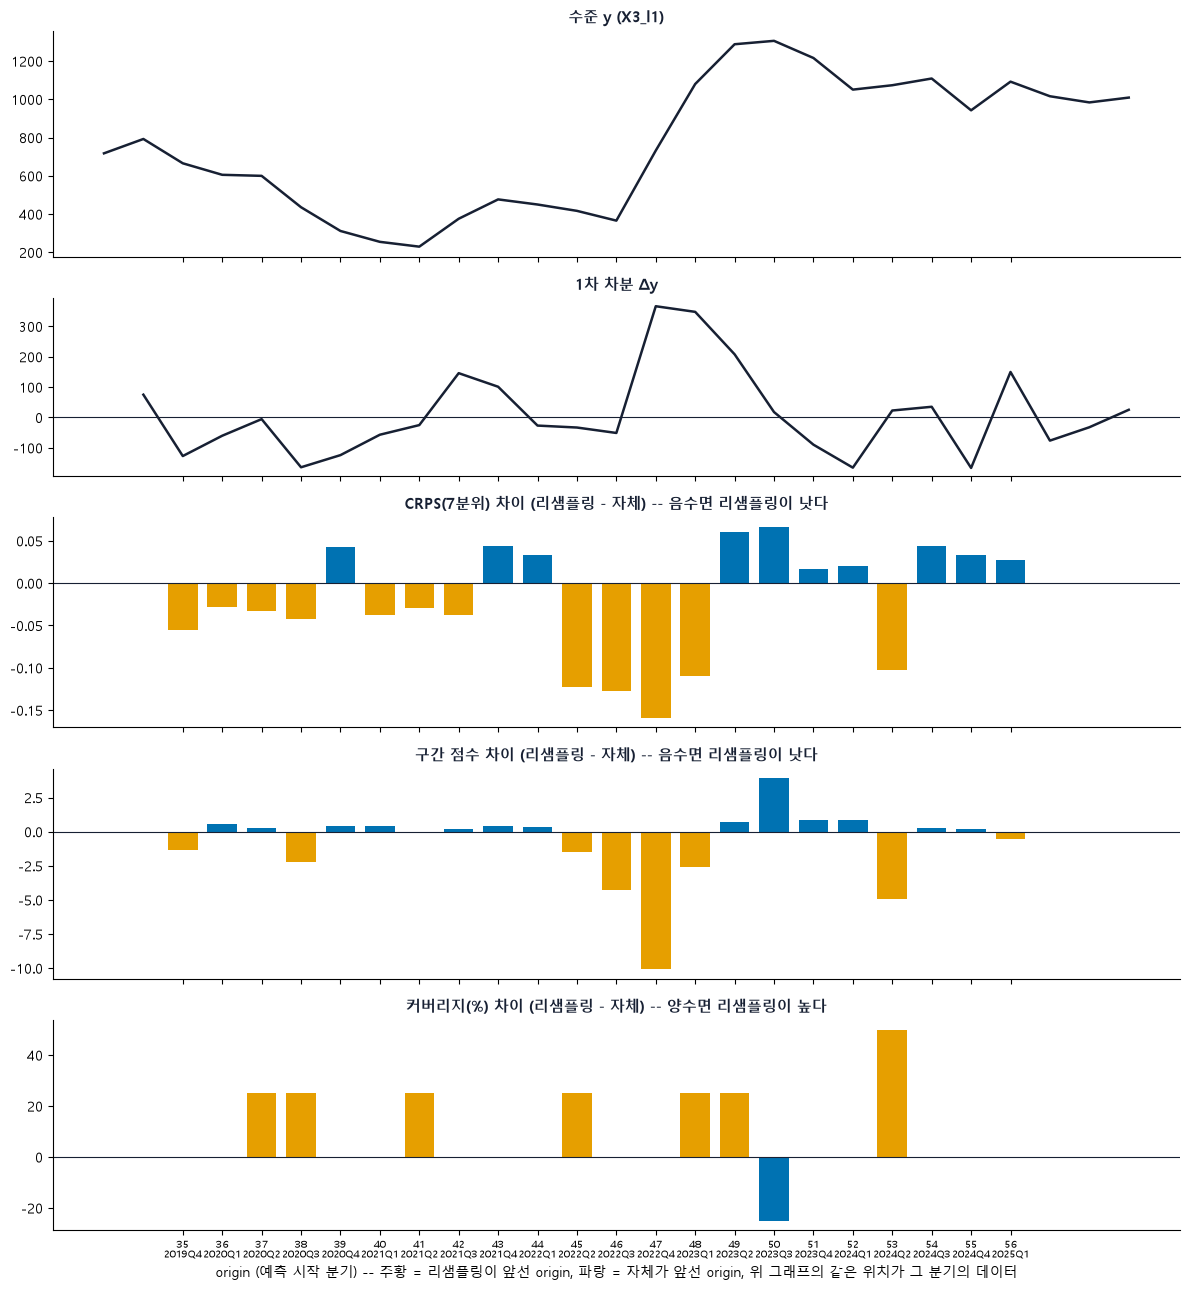

In [8]:
xl2 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.3, 1.3, 1.3]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
for ax, c, t, good_neg in [(axes[2], "CRPS(7분위)", "CRPS(7분위) 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[3], "구간점수", "구간 점수 차이 (리샘플링 - 자체) -- 음수면 리샘플링이 낫다", True),
                           (axes[4], "적중", "커버리지(%) 차이 (리샘플링 - 자체) -- 양수면 리샘플링이 높다", False)]:
    v = dif[c].values
    good = (v < 0) if good_neg else (v > 0)
    ax.bar(scored_origins, v, color=np.where(good, "#E69F00", "#0072B2"), width=0.75)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t, fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[4].set_xticks(scored_origins)
axes[4].set_xticklabels(xl2, fontsize=7)
axes[4].set_xlabel("origin (예측 시작 분기) -- 주황 = 리샘플링이 앞선 origin, 파랑 = 자체가 앞선 origin, 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


### 5-1. 같은 폭에서 비교 -- 구간 점수와 90% 도달 배율


In [9]:
LOGMODE = False


def interval_at(g, k):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if LOGMODE:
        lo_k = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        hi_k = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        lo_k, hi_k = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= lo_k) & (a <= hi_k)) * 100
    width = np.mean(hi_k - lo_k) / var_std
    iscore = np.mean((hi_k - lo_k) + (2 / ALPHA_IS) * np.maximum(lo_k - a, 0) + (2 / ALPHA_IS) * np.maximum(a - hi_k, 0)) / var_std
    return cov, width, iscore


rows = []
for name in ["리샘플링", "자체"]:
    g = DF[DF["방식"] == name]
    cov1, w1, is1 = interval_at(g, 1.0)
    ks = np.linspace(0.2, 8, 1561)
    k90 = next((k for k in ks if interval_at(g, k)[0] >= 90), np.nan)
    cov90, w90, is90 = interval_at(g, k90) if not np.isnan(k90) else (np.nan, np.nan, np.nan)
    rows.append({"방식": name, "원래 커버리지(%)": cov1, "원래 폭": w1, "원래 구간점수": is1,
                 "90% 도달 배율 k": k90, "그때의 폭": w90, "그때의 구간점수": is90})
display(pd.DataFrame(rows).set_index("방식").round(3))
print("k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.")


,원래 커버리지(%),원래 폭,원래 구간점수,90% 도달 배율 k,그때의 폭,그때의 구간점수
방식,,,,,,
리샘플링,69.318,2.227,5.497,1.685,3.753,4.712
자체,61.364,1.705,6.327,1.865,3.180,4.914


k < 1이면 구간을 줄여도 90%에 도달(원래 구간이 넓음), k > 1이면 늘려야 90%에 도달한다. 폭과 구간점수는 var_std로 나눈 값이다.


### 5-2. 결론 (원 스케일)

**리샘플링이 평균적으로 약간 낫지만 일관되지는 않다. 리샘플링의 커버리지 이점은 상당 부분 구간이 넓어서 생긴 것이다.**

- **평균 차이는 작고 일관되지 않다**: CRPS 평균 차이 -0.023, 중앙값 -0.029이고, 리샘플링이 앞선 origin은 12개, 뒤진 origin은 10개다. 구간 점수는 앞선 9개 대 뒤진 13개로 엇갈린다.
- **커버리지 차이는 8개 origin에 몰려 있다**(리샘플링이 높은 7개, 낮은 1개, 14개는 같음).
- **같은 90%로 맞추면 차이가 작아진다**:

| 방식 | 원래 커버리지 | 원래 구간점수 | 90% 도달 k | 그때의 폭 | 그때의 구간점수 |
|---|---|---|---|---|---|
| 리샘플링 | 69.3% | 5.50 | 1.69 | 3.75 | 4.71 |
| 자체 | 61.4% | 6.33 | 1.87 | 3.18 | 4.91 |

  90%로 맞추면 구간 점수 차이가 작고(4.71 vs 4.91) 리샘플링의 폭이 더 넓다(3.75 vs 3.18). 구간의 모양이 뚜렷하게 더 낫다고 보기는 어렵다.

**한계**: 22개 origin이 겹쳐 있고 유의성 검정은 하지 않았다. "차이가 없다"를 통계적으로 증명한 것은 아니다.

## 6. 리샘플링 구간이 넓은 이유와 h별 특징

리샘플링 구간이 자체보다 넓은 이유를 두 가설로 본다. 구간을 늘려 90%를 맞추는 k_h는 평가가 아니라 **진단용**이다.

- **가설 1**: 모델 σ는 훈련 오차에서 추정되는데 리샘플링은 실제 out-of-sample 오차를 쓴다. 후자가 크면 구간이 넓다.
- **가설 2**: 큰 충격(급등)의 오차가 표본에 남아 이후 구간을 계속 넓힌다.
- **h별**: σ가 h에 따라 커지는 정도가 실제 오차와 맞는가.

In [10]:
DF = res.copy()
r = DF[DF["방식"] == "리샘플링"].set_index(["origin", "h"])
s = DF[DF["방식"] == "자체"].set_index(["origin", "h"])
sigma = s["sigma_model"]                       # 모델 σ (원 단위)
err = r['actual'] - r['fc']                                    # 점예측 오차 (원 단위)
z = err / sigma
dd = pd.DataFrame({"오차": err, "σ": sigma, "z": z, "오차표본std": r["pool_std"], "오차표본최대": r["pool_absmax"],
                   "폭비율": (r['hi'] - r['lo']) / (s['hi'] - s['lo']), "표본n": r["pool_n"]})
dd["표본std/σ"] = dd["오차표본std"] / dd["σ"]

print("전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ:", round(dd["표본std/σ"].mean(), 3), " / 구간 폭 비율(리샘플링÷자체):", round(dd["폭비율"].mean(), 3))
print("실제 오차(88개)의 표준편차 ÷ 모델 σ 평균:", round(dd["오차"].std() / dd["σ"].mean(), 3))


전체 평균 -- 오차 표본 표준편차 ÷ 모델 σ: 1.287  / 구간 폭 비율(리샘플링÷자체): 1.314
실제 오차(88개)의 표준편차 ÷ 모델 σ 평균: 2.068


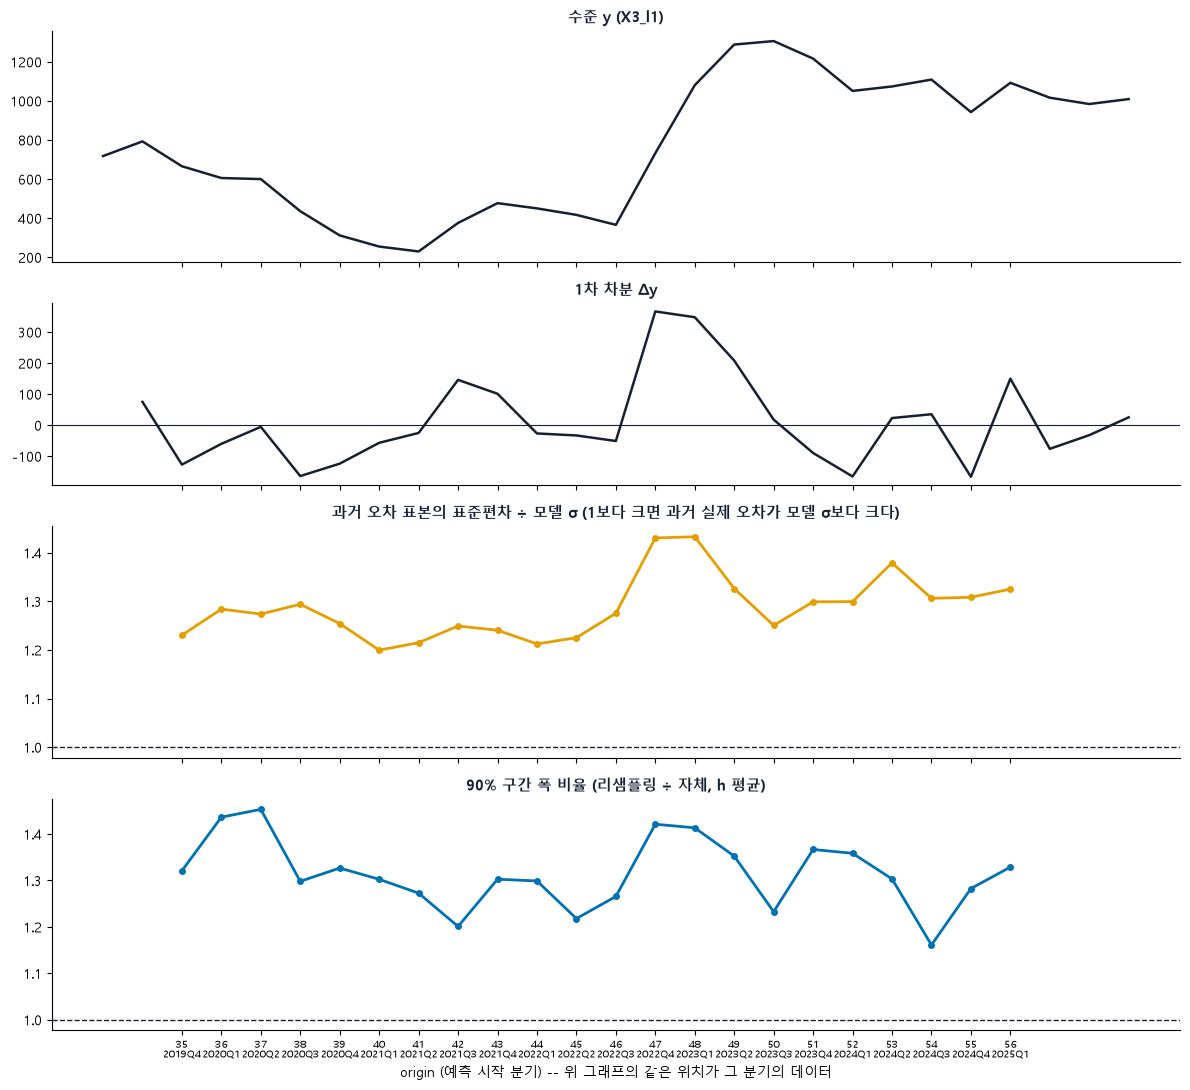

구간별 평균:


,표본std/σ,폭비율
origin 35~46,1.246,1.308
origin 47~56,1.336,1.322


In [11]:
per_o = dd.groupby("origin")[["표본std/σ", "폭비율"]].mean()
xl3 = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = scored_origins[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.1, 1.4, 1.4]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
axes[2].plot(scored_origins, per_o["표본std/σ"].values, marker="o", ms=4, color="#E69F00", linewidth=2)
axes[2].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[2].set_title("과거 오차 표본의 표준편차 ÷ 모델 σ (1보다 크면 과거 실제 오차가 모델 σ보다 크다)", fontsize=11, fontweight="bold", color="#172033")
axes[3].plot(scored_origins, per_o["폭비율"].values, marker="o", ms=4, color="#0072B2", linewidth=2)
axes[3].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[3].set_title("90% 구간 폭 비율 (리샘플링 ÷ 자체, h 평균)", fontsize=11, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl3, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()

print("구간별 평균:")
split = np.where(per_o.index <= 46, "origin 35~46", "origin 47~56")
display(per_o.groupby(split).mean().round(3))


### 6-1. h별 특징

h=1~4마다 실제 오차의 표준편차, 모델 σ, 둘의 비율, h=1 대비 증가율과 진단용 `k_h`(`|z|`의 90분위 ÷ 1.645)를 본다.

,실제 오차 표준편차,모델 σ 평균,오차 표본 표준편차 평균,리샘플링÷자체 폭,k_h (진단),오차÷σ,오차 증가율(h=1=1),σ 증가율(h=1=1)
h,,,,,,,,
1,149.095,69.819,85.212,1.389,1.751,2.135,1.000,1.000
2,264.120,126.779,164.099,1.286,1.762,2.083,1.771,1.816
3,343.141,174.501,229.182,1.239,1.529,1.966,2.301,2.499
4,410.214,214.858,287.103,1.343,2.054,1.909,2.751,3.077


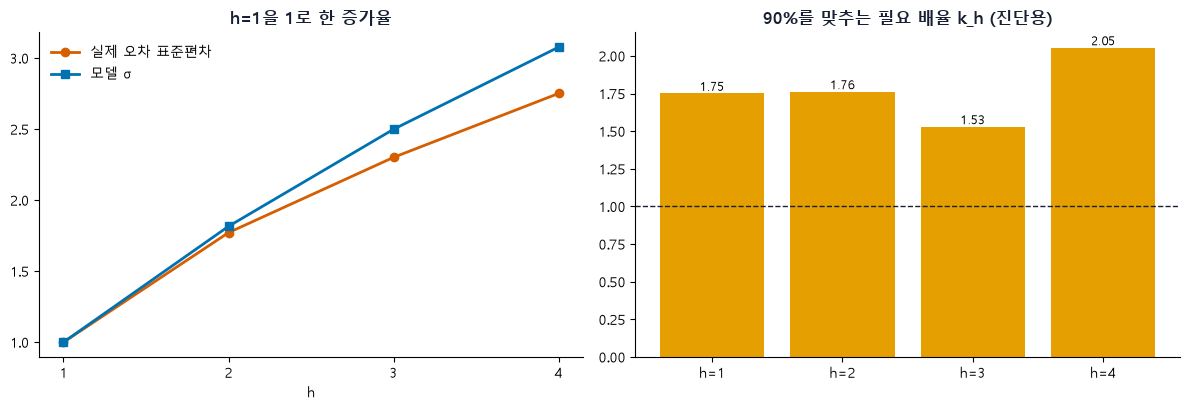

In [12]:
hg = dd.groupby("h")
htab = pd.DataFrame({
    "실제 오차 표준편차": hg["오차"].std(),
    "모델 σ 평균": hg["σ"].mean(),
    "오차 표본 표준편차 평균": hg["오차표본std"].mean(),
    "리샘플링÷자체 폭": hg["폭비율"].mean(),
    "k_h (진단)": hg["z"].apply(lambda x: np.quantile(np.abs(x), 0.9) / Z),
})
htab["오차÷σ"] = htab["실제 오차 표준편차"] / htab["모델 σ 평균"]
htab["오차 증가율(h=1=1)"] = htab["실제 오차 표준편차"] / htab["실제 오차 표준편차"].iloc[0]
htab["σ 증가율(h=1=1)"] = htab["모델 σ 평균"] / htab["모델 σ 평균"].iloc[0]
display(htab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hs = htab.index.values
axes[0].plot(hs, htab["오차 증가율(h=1=1)"], marker="o", color="#D55E00", linewidth=2, label="실제 오차 표준편차")
axes[0].plot(hs, htab["σ 증가율(h=1=1)"], marker="s", color="#0072B2", linewidth=2, label="모델 σ")
axes[0].set_xticks(hs)
axes[0].set_title("h=1을 1로 한 증가율", fontsize=12, fontweight="bold", color="#172033")
axes[0].set_xlabel("h")
axes[0].legend(frameon=False)
bars = axes[1].bar([f"h={h}" for h in hs], htab["k_h (진단)"], color="#E69F00")
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(1, color="#172033", linestyle="--", linewidth=1)
axes[1].set_title("90%를 맞추는 필요 배율 k_h (진단용)", fontsize=12, fontweight="bold", color="#172033")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### 6-2. 결론 (원 스케일)

**리샘플링 구간이 넓은 이유는 과거 실제 오차가 모델 σ보다 크기 때문이다.**

- **가설 1 맞음**: 오차 표본의 표준편차가 모델 σ의 1.29배, 리샘플링 폭이 자체의 1.31배로 거의 일치한다.
- **가설 2는 약함**: 급등 전후 비율이 1.25와 1.34로 뚜렷한 차이가 없다.
- **둘 다 실제 오차보다 좁다**: 평가 구간의 실제 오차 표준편차는 모델 σ의 2.07배(과거 표본의 1.29배보다 큼). 평가 구간에 과거에 없던 급등이 있다.
- **h별**:

| h | 오차÷σ | 오차 증가율 | σ 증가율 | k_h (진단) |
|---|---|---|---|---|
| 1 | 2.14 | 1.00 | 1.00 | 1.75 |
| 2 | 2.08 | 1.77 | 1.82 | 1.76 |
| 3 | 1.97 | 2.30 | 2.50 | 1.53 |
| 4 | 1.91 | 2.75 | 3.08 | 2.05 |

  - σ는 **h=1부터 이미 오차의 절반 수준**이다. 문제는 증가율이 아니라 σ의 **수준**이다.
  - 오히려 σ는 h가 커질수록 오차보다 더 빨리 커진다(h=4: σ 3.08배 vs 오차 2.75배).
  - k_h는 h마다 크게 다르지 않아 h별 보정의 필요는 작다(h별 커버리지의 들쭉날쭉함은 22개 표본의 잡음 가능성).

**한계**: 22개 origin이 겹쳐 유의성 검정은 하지 않았다. k_h는 진단용이다.